# Formative 3: Probability Distributions, Bayesian Probability and Gradient Descent

**Mathematics for Machine Learning, African Leadership University. Group 13.**

| Part | Topic | Owner | Folder |
|---|---|---|---|
| 1 | EM algorithm for a mixture of two Gaussians (Galton heights) | Alieu O Jobe | `part1_em_algorithm/` |
| 2 | Bayes' theorem on IMDb reviews, P(Positive \| keyword) | Igor Ntwali | `part2_bayesian/` |
| 3 | Gradient descent by hand, 3 updates in matrix form | Gatete Derrick | `part3_Gradient_Descent_Manual_Calculation/` |
| 4 | Gradient descent in Python with a SciPy derivative and plots | Igor Ntwali | `part4_gradient_descent/` |

This notebook runs every part through the same tested modules each part folder uses (`em_gmm.py`, `bayes_imdb.py`, `gradient_descent.py`, `plots.py`), so no logic is copied here. Each folder also has its own detailed notebook.

In [1]:
# Setup: works locally (run from the repo root) and on Google Colab.
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/igorntwari/ml-formative-3-probability-bayes-gradient-descent.git"
if "google.colab" in sys.modules and not Path("part1_em_algorithm").exists():
    if not Path("ml-formative-3-probability-bayes-gradient-descent").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("ml-formative-3-probability-bayes-gradient-descent")

ROOT = Path.cwd()
for folder in ("part1_em_algorithm", "part2_bayesian", "part4_gradient_descent"):
    sys.path.insert(0, str(ROOT / folder))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.float_format", "{:.4f}".format)
print("Repo root:", ROOT.name)

Repo root: ml-formative-3-probability-bayes-gradient-descent


---
## Part 1: Expectation Maximization on Galton heights

We pool 934 children and 205 fathers (one per family), hide the labels, and fit a mixture of two Gaussians with EM written from scratch in NumPy.

**Should you split at the global mean and average each pile? No.** It assumes the groups do not overlap, it biases the means outward and shrinks both variances (truncation bias), the mixing weights come from the cut instead of the data, and it gives hard labels with no probabilities. EM gives soft assignments (responsibilities) and climbs the log likelihood until it stops improving. We use the mean split only as iteration 0.

**E step:** $r_{ik}=\dfrac{\pi_k\,\mathcal{N}(x_i\mid\mu_k,\sigma_k^2)}{\sum_j\pi_j\,\mathcal{N}(x_i\mid\mu_j,\sigma_j^2)}$  **M step:** $N_k=\sum_i r_{ik},\;\mu_k=\tfrac{1}{N_k}\sum_i r_{ik}x_i,\;\sigma_k^2=\tfrac{1}{N_k}\sum_i r_{ik}(x_i-\mu_k)^2,\;\pi_k=\tfrac{N_k}{N}$

**Stop** when the log likelihood $\mathcal{L}=\sum_i\log\sum_k\pi_k\mathcal{N}(x_i\mid\mu_k,\sigma_k^2)$ improves by less than $10^{-6}$.

In [2]:
from em_gmm import decision_boundary, fit_em, load_heights, mean_split_estimate, posterior, tracking_table

heights, labels = load_heights(ROOT / "part1_em_algorithm" / "data" / "GaltonFamilies.csv", parent="father")
history = fit_em(heights, init=mean_split_estimate(heights))
final = history[-1].params
table = tracking_table(history, ("Child", "Father"))

print(f"{heights.size} heights. Converged after {history[-1].iteration} iterations.")
print("Tracking table (initialization, first two iterations, converged):")
display(table.loc[[0, 1, 2, history[-1].iteration]])
print(f"Decision boundary: {decision_boundary(final, 40, 100)[0]:.2f} in")

1139 heights. Converged after 309 iterations.
Tracking table (initialization, first two iterations, converged):


,mu1 (Child),mu2 (Father),sigma1^2,sigma2^2,pi1,pi2,Log Likelihood
Iteration,,,,,,,
0,64.2598,70.2147,4.1428,3.5711,0.5048,0.4952,-3071.1165
1,64.3784,70.0758,4.9168,4.2979,0.5033,0.4967,-3053.5777
2,64.4368,69.9988,5.3058,4.6724,0.5017,0.4983,-3049.7088
309,64.1772,69.5186,5.3024,6.0410,0.4325,0.5675,-3046.9895


Decision boundary: 66.54 in


In [3]:
# Live demo: change the test height (UNIT = "cm" if given in centimetres) and run this cell.
TEST_HEIGHT = 70.0
UNIT = "in"

p_child, p_father = posterior(TEST_HEIGHT, final, unit=UNIT)
print(f"Test height {TEST_HEIGHT} {UNIT}:  P(Child) = {p_child:.6f}   P(Father) = {p_father:.6f}")
print("Prediction:", "Child" if p_child > p_father else "Father")

Test height 70.0 in:  P(Child) = 0.032786   P(Father) = 0.967214
Prediction: Father


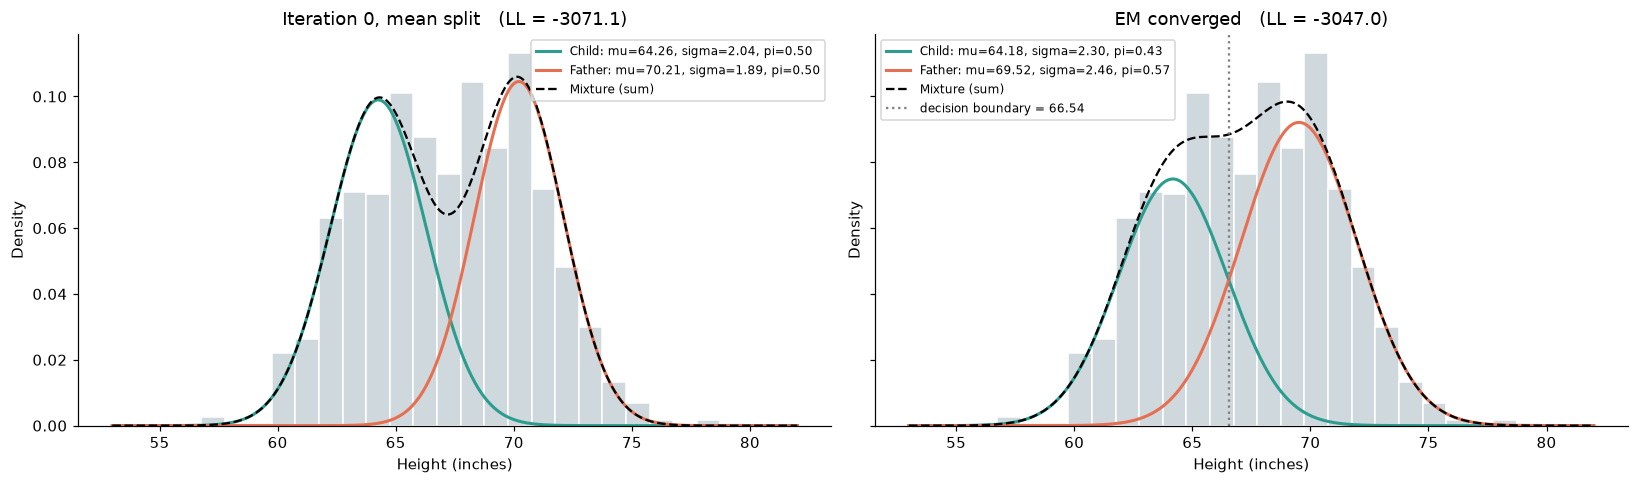

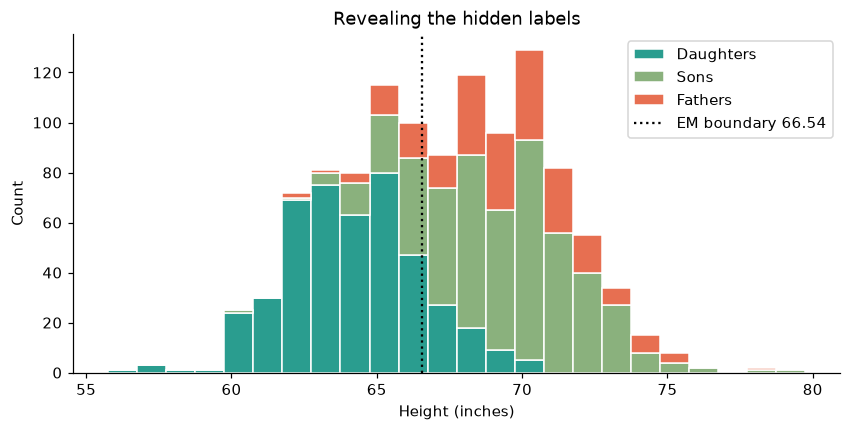

In [4]:
display(Image(filename=str(ROOT / "part1_em_algorithm" / "figures" / "04_mean_split_vs_em.png")))
display(Image(filename=str(ROOT / "part1_em_algorithm" / "figures" / "05_hidden_labels.png")))

**Key finding.** EM converges to 64.2 and 69.5 inches. Revealing the hidden labels shows these are daughters (64.1) against sons and fathers (69.2 and 69.3): the children are both sexes, so the strongest two Gaussian structure is sex, not generation. EM maximised the likelihood correctly; the "Child / Father" names do not hold. On fathers vs daughters only, EM beats the mean split (accuracy 86% vs 81%, daughters' variance 4.75 vs 2.94 against a true 5.54). Full analysis: `part1_em_algorithm/part1_em_algorithm.ipynb`.

---
## Part 2: Bayesian probability on IMDb reviews

We compute **P(Positive | keyword)** only, with basic Python (`csv`, `re`), counting each keyword once per review:
$P(\text{Pos}\mid kw)=\dfrac{P(kw\mid\text{Pos})\,P(\text{Pos})}{P(kw)}$.
Keywords: excellent, wonderful, superb, amazing (positive) and worst, awful, terrible, waste (negative). The reasons for each choice are in `part2_bayesian/part2_bayes.ipynb`.

The 50,000 review dataset (66 MB) is not committed. Download `IMDB Dataset.csv` from the Kaggle link in the brief into `part2_bayesian/`.

In [5]:
from bayes_imdb import NEGATIVE_KEYWORDS, POSITIVE_KEYWORDS, analyze_keyword, direct_posterior, load_reviews

IMDB = ROOT / "part2_bayesian" / "IMDB Dataset.csv"
if IMDB.exists():
    reviews = load_reviews(IMDB)
    n_total = len(reviews)
    n_pos = sum(1 for _, label in reviews if label == "positive")
    results = [analyze_keyword(reviews, k, n_total, n_pos) for k in POSITIVE_KEYWORDS + NEGATIVE_KEYWORDS]
    bayes_table = pd.DataFrame(results).set_index("keyword")
    bayes_table.columns = ["Prior P(Positive)", "Likelihood P(kw|Positive)", "Marginal P(kw)", "Posterior P(Positive|kw)"]
    print(f"{n_total} reviews, {n_pos} positive")
    display(bayes_table)
    assert all(abs(r["posterior"] - direct_posterior(reviews, r["keyword"])) < 1e-9 for r in results)
    print("Check passed: every Bayes posterior equals the direct count (positive with keyword / all with keyword).")
else:
    print(f"Dataset not found. Download 'IMDB Dataset.csv' into {IMDB.parent} and rerun this cell.")

50000 reviews, 25000 positive


,Prior P(Positive),Likelihood P(kw|Positive),Marginal P(kw),Posterior P(Positive|kw)
keyword,,,,
excellent,0.5000,0.1146,0.0710,0.8073
wonderful,0.5000,0.0902,0.0555,0.8120
superb,0.5000,0.0410,0.0240,0.8557
amazing,0.5000,0.0671,0.0431,0.7783
worst,0.5000,0.0164,0.0886,0.0924
awful,0.5000,0.0112,0.0575,0.0977
terrible,0.5000,0.0152,0.0539,0.1413
waste,0.5000,0.0070,0.0507,0.0687


Check passed: every Bayes posterior equals the direct count (positive with keyword / all with keyword).


Positive keywords raise the probability from the 0.50 prior to between 0.78 and 0.86; negative keywords lower it to between 0.07 and 0.14. A frequent word that appears in both classes, such as "good", stays near 0.49 and carries almost no information.

---
## Part 3: Gradient descent by hand

Model in matrix form: $\hat y = Xm + b$ with $X=\begin{bmatrix}1&3\\4&10\end{bmatrix}$, $m_0=\begin{bmatrix}-1\\2\end{bmatrix}$, $b_0=\begin{bmatrix}1\\1\end{bmatrix}$, $y=\begin{bmatrix}5\\6\end{bmatrix}$, learning rate $\alpha=0.01$, cost $J=\tfrac1n e^Te$ with $e=\hat y-y$.

**Chain rule:** $\dfrac{\partial J}{\partial m}=\dfrac{\partial J}{\partial e}\dfrac{\partial e}{\partial m}=\tfrac2n X^Te$ and $\dfrac{\partial J}{\partial b}=\dfrac{\partial J}{\partial e}\dfrac{\partial e}{\partial b}=\tfrac2n e$; with $n=2$, $\tfrac2n=1$.

The handwritten calculations (`part3_Gradient_Descent_Manual_Calculation/`):

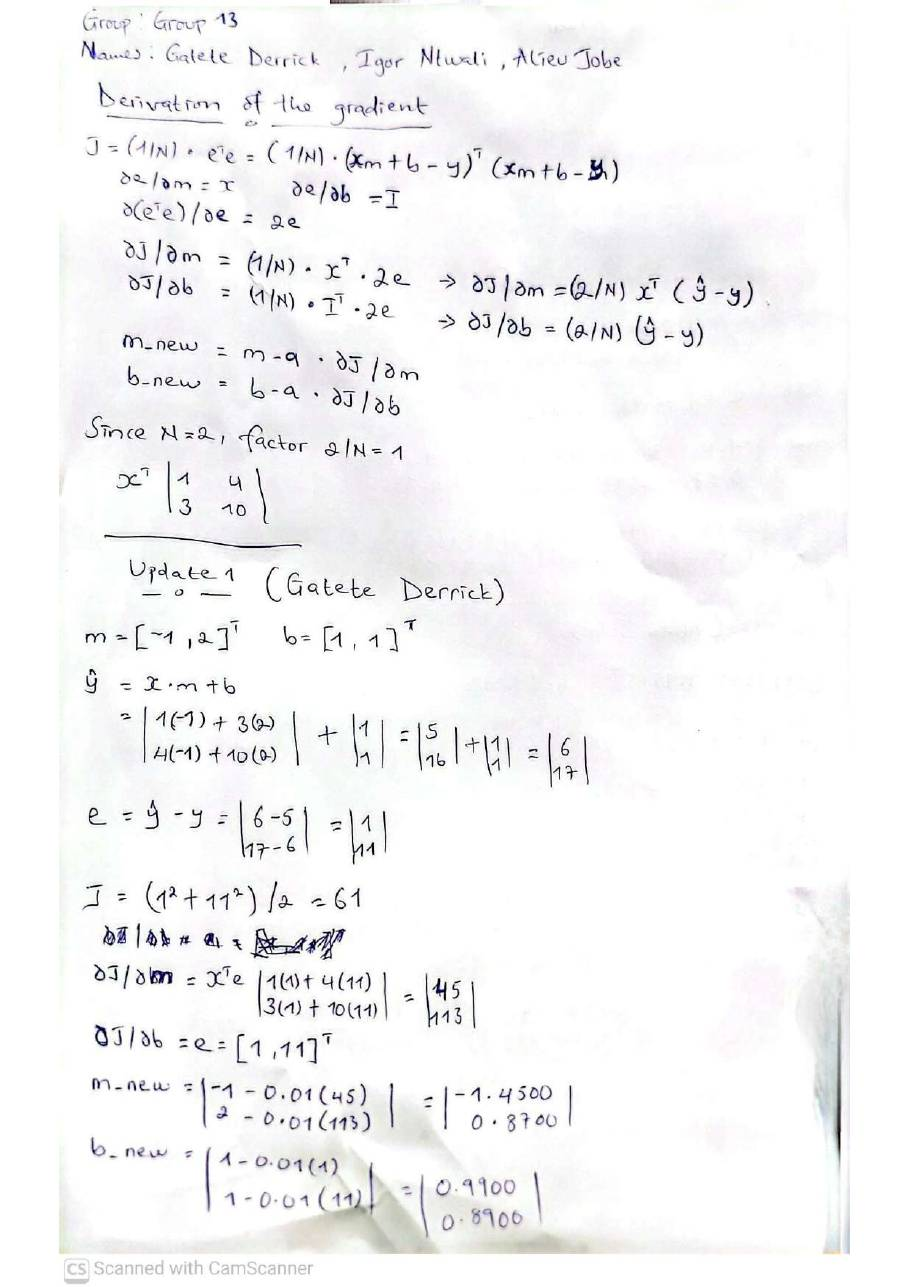

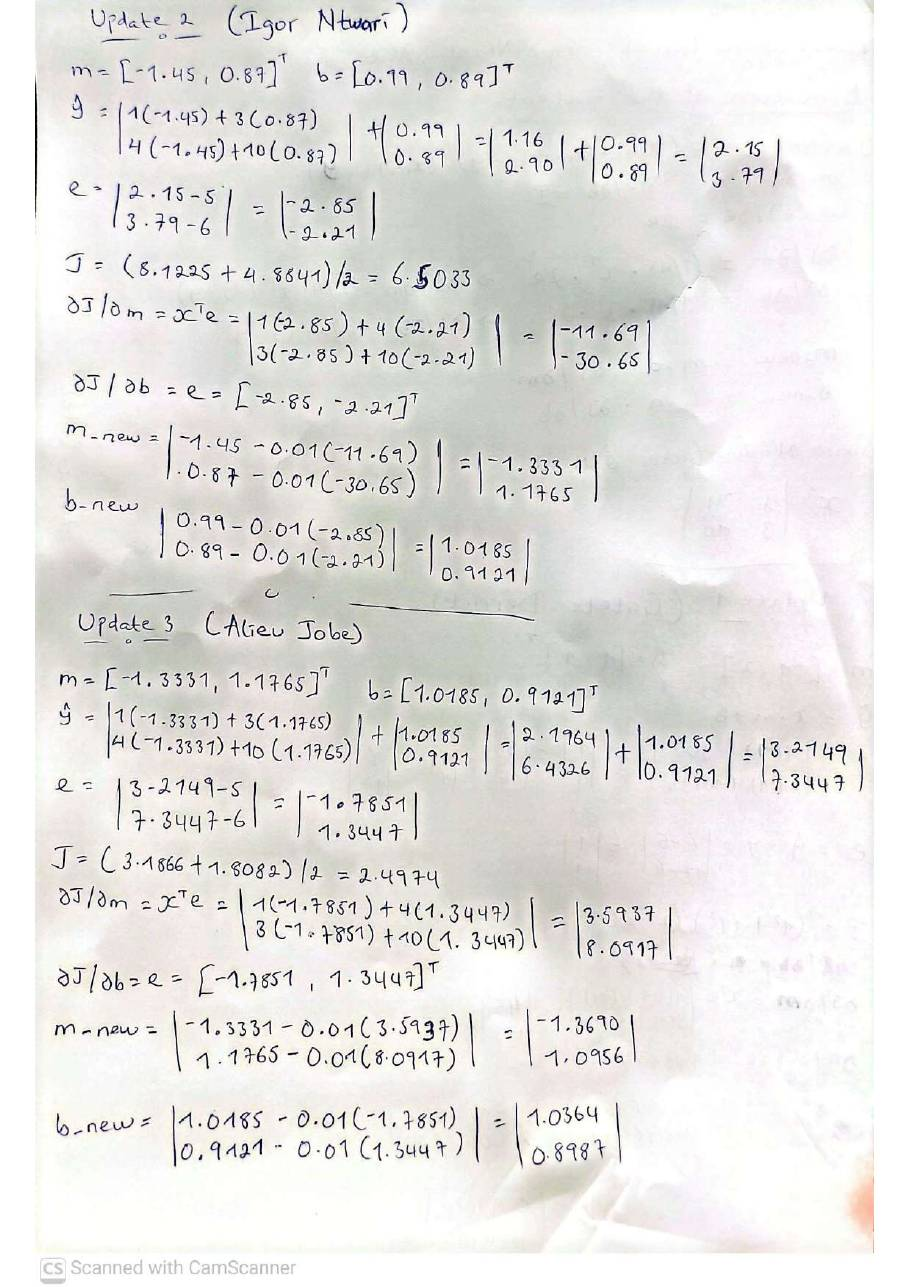

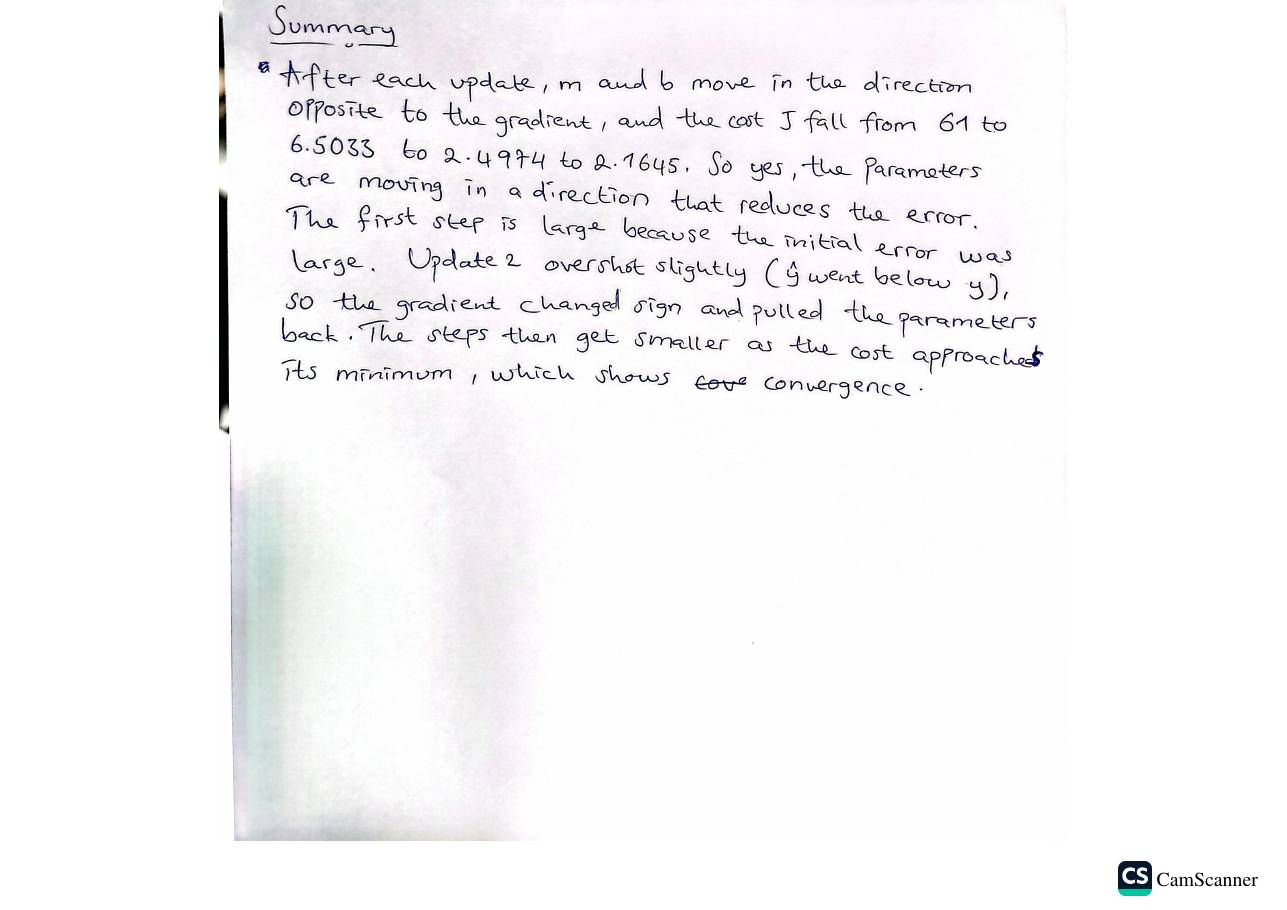

In [6]:
part3 = ROOT / "part3_Gradient_Descent_Manual_Calculation"
for page in sorted(part3.glob("page*.jpg")):   # every scanned page, in order
    display(Image(filename=str(page), width=650))

| After update | m | b | Cost J at these m, b |
|---|---|---|---|
| 0 (start) | [−1, 2] | [1, 1] | 61 |
| 1 | [−1.45, 0.87] | [0.99, 0.89] | 6.5033 |
| 2 | [−1.3331, 1.1765] | [1.0185, 0.9121] | 2.4974 |
| 3 | [−1.369037, 1.095583] | [1.036351, 0.898653] | 2.1645 |

**Trend.** The cost falls at every update, so m and b move in a direction that reduces the error. The first step is large because the starting error is large (11 on the second point). After it, m2 and b swing back slightly (overshoot, then correct) because α = 0.01 is close to the stability limit of about 0.0158 for this data, so the path zigzags as it settles.

---
## Part 4: Gradient descent in code

The same three updates, computed in Python with every intermediate value printed so they can be checked line by line against Part 3. The gradient is computed two ways, by the chain rule and by a SciPy derivative function that takes an equation and returns its derivative, and the two agree.

In [7]:
from gradient_descent import B0, M0, X, Y, analytic_gradient, build_history, derivative_of, describe_step, predict, run_gradient_descent, scipy_gradient
from plots import plot_cost, plot_parameters

LEARNING_RATE = 0.01
print("SciPy derivative of x^3 at x = 2 (exact answer 12):", round(derivative_of(lambda x: x**3, 2.0), 4))
gm_a, gb_a = analytic_gradient(X, Y, M0, B0)
gm_s, gb_s = scipy_gradient(X, Y, M0, B0)
assert np.allclose(gm_a, gm_s, atol=1e-3) and np.allclose(gb_a, gb_s, atol=1e-3)
print("Chain rule gradient:", gm_a, gb_a, "| SciPy gradient:", np.round(gm_s, 3), np.round(gb_s, 3), "\n")

steps, _, _ = run_gradient_descent(X, Y, M0, B0, LEARNING_RATE, 3)
for number, step in enumerate(steps, start=1):
    describe_step(number, step, LEARNING_RATE)

SciPy derivative of x^3 at x = 2 (exact answer 12): 12.0
Chain rule gradient: [ 45. 113.] [ 1. 11.] | SciPy gradient: [ 45. 113.] [ 1. 11.] 

--- Update 1 ---
m      = [-1.  2.]   b = [1. 1.]
y_hat  = X @ m + b = [ 6. 17.]
error  = y_hat - y = [ 1. 11.]
cost J = 61.000000
dJ/dm  = (2/n) X^T e = [ 45. 113.]
dJ/db  = (2/n) e     = [ 1. 11.]
new m  = m - 0.01 * dJ/dm = [-1.45  0.87]
new b  = b - 0.01 * dJ/db = [0.99 0.89]

--- Update 2 ---
m      = [-1.45  0.87]   b = [0.99 0.89]
y_hat  = X @ m + b = [2.15 3.79]
error  = y_hat - y = [-2.85 -2.21]
cost J = 6.503300
dJ/dm  = (2/n) X^T e = [-11.69 -30.65]
dJ/db  = (2/n) e     = [-2.85 -2.21]
new m  = m - 0.01 * dJ/dm = [-1.3331  1.1765]
new b  = b - 0.01 * dJ/db = [1.0185 0.9121]

--- Update 3 ---
m      = [-1.3331  1.1765]   b = [1.0185 0.9121]
y_hat  = X @ m + b = [3.2149 7.3447]
error  = y_hat - y = [-1.7851  1.3447]
cost J = 2.497400
dJ/dm  = (2/n) X^T e = [3.5937 8.0917]
dJ/db  = (2/n) e     = [-1.7851  1.3447]
new m  = m - 0.01 * dJ/dm

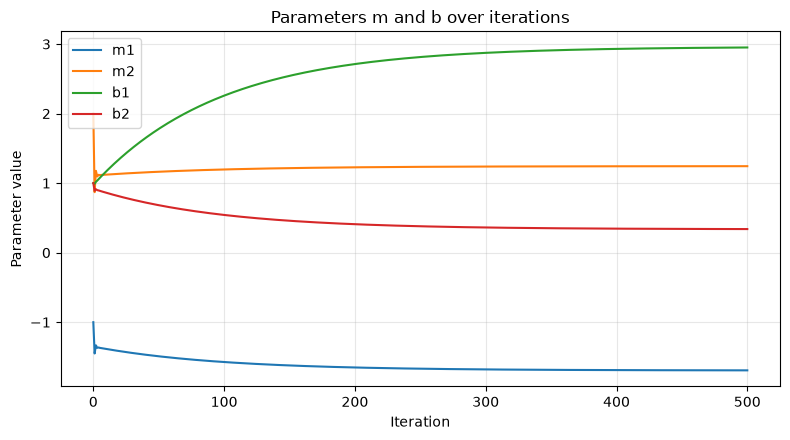

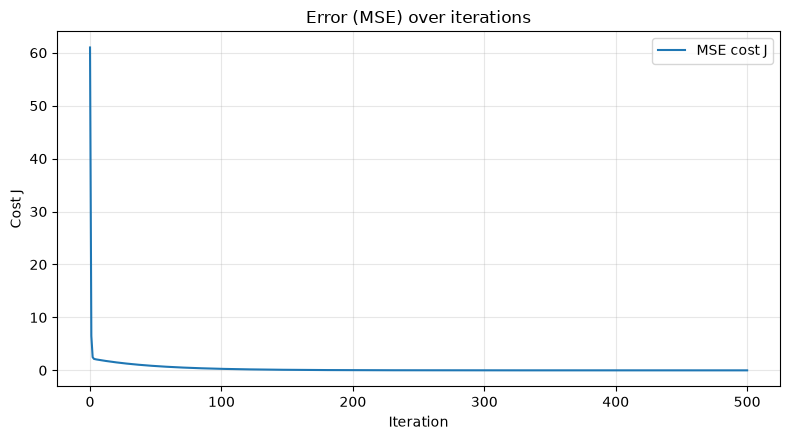

Final m = [-1.69273666  1.24351723]  Final b = [2.95071776 0.33913639]
Predictions: [4.98853278 6.003362  ]  Actual: [5. 6.]
Cost: 61.0000 at the start, 0.000071 after 500 iterations


In [8]:
steps, m_final, b_final = run_gradient_descent(X, Y, M0, B0, LEARNING_RATE, 500)
history_gd = build_history(steps, X, Y, m_final, b_final)
plot_parameters(history_gd)
plot_cost(history_gd)
print("Final m =", m_final, " Final b =", b_final)
print("Predictions:", predict(X, m_final, b_final), " Actual:", Y)
print(f"Cost: {history_gd['cost'][0]:.4f} at the start, {history_gd['cost'][-1]:.6f} after 500 iterations")